- Uses BiomedCLIP, multimodal medical model
- Vision transformer uses timm library
- Attention dropout: regularization trick for training. Reduce overfitting by zeroing out a portion of values
- Forward hook: attach a function to a module (PyTorch) to observe model inputs and outputs

- extract a **14×14 image attention map** (attention rollout). 224x224 image -> 16x16 patches, 14x14 grid

In [1]:
%pip install -q open_clip_torch transformers pillow matplotlib

Note: you may need to restart the kernel to use updated packages.


  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.


In [ ]:
import torch, torch.nn.functional as F
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
from open_clip import create_model_from_pretrained, get_tokenizer

HUB = "hf-hub:microsoft/BiomedCLIP-PubMedBERT_256-vit_base_patch16_224" # BiomedCLIP pretrained model
IMAGE_PATH = "chest_xray.jpg"

c:\Users\Charlotte\miniconda3\envs\astra_env\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [ ]:
class BiomedCLIPService:
    def __init__(self, device=None):
        self.device = device or ("cuda" if torch.cuda.is_available() else "cpu")
        self.model, self.preprocess = create_model_from_pretrained(HUB)
        self.tokenizer = get_tokenizer(HUB)
        self.model.to(self.device).eval()
        
        # Capture attention weights per layer for vision by disabling timm fused attention and using a forward
        # hook for attention dropout
        self._attn = []
        for blk in self.model.visual.trunk.blocks:
            blk.attn.fused_attn = False
            blk.attn.attn_drop.register_forward_hook(lambda m, inp, out: self._attn.append(inp[0].detach()))

    @torch.no_grad()
    def predict(self, image: Image.Image, prompts: dict):
        """prompts: {label: text prompt}. Returns ({label: prob}, 14x14 attention tensor)."""
        self._attn.clear()
        x = self.preprocess(image.convert("RGB")).unsqueeze(0).to(self.device)
        t = self.tokenizer(list(prompts.values()), context_length=256).to(self.device)

        img = F.normalize(self.model.encode_image(x), dim=-1)
        txt = F.normalize(self.model.encode_text(t), dim=-1)
        probs = (self.model.logit_scale.exp() * img @ txt.T).softmax(-1)[0].cpu()
        return dict(zip(prompts, probs.tolist())), self._rollout()

    def _rollout(self):
        """Attention rollout: multiply head-averaged, residual-corrected attention across layers."""
        r = None
        for a in self._attn:
            a = a.mean(1) # average heads -> (B, N, N)
            a = a + torch.eye(a.size(-1), device=a.device) # account for residual connection
            a = a / a.sum(-1, keepdim=True)
            r = a if r is None else a @ r

        cls_to_patches = r[0, 0, 1:] # [CLS] row, drop the [CLS] column
        n = int(cls_to_patches.numel() ** 0.5)    
        return cls_to_patches.reshape(n, n).cpu()

In [ ]:
svc = BiomedCLIPService()
print("device:", svc.device)

# (1, 12 heads, 197, 197) attention
_ = svc.predict(Image.new("RGB", (224, 224)), {"x": "chest X-ray"})
print(len(svc._attn), "layers captured, shape", tuple(svc._attn[0].shape))

device: cpu
12 layers captured, shape (1, 12, 197, 197)


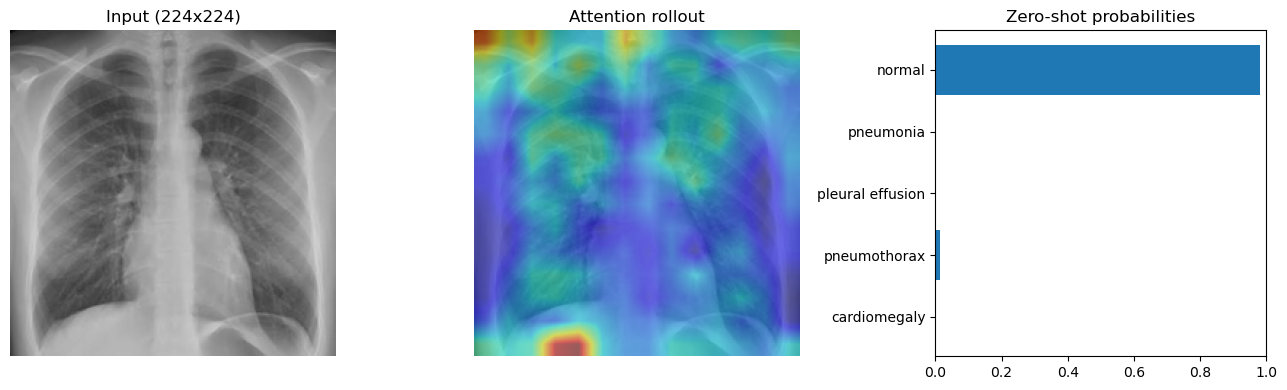

{'normal': 0.981, 'pneumonia': 0.003, 'pleural effusion': 0.0, 'pneumothorax': 0.015, 'cardiomegaly': 0.001}


In [7]:
PROMPTS = {
    "normal":           "normal chest X-ray with no acute findings",
    "pneumonia":        "chest X-ray showing pneumonia",
    "pleural effusion": "chest X-ray showing pleural effusion",
    "pneumothorax":     "chest X-ray showing pneumothorax",
    "cardiomegaly":     "chest X-ray showing cardiomegaly",
}

def show(image, probs, heat, alpha=0.5):
    # Mirror the model's preprocessing (resize + center crop to 224) so the overlay aligns.
    base = ImageOps.fit(image.convert("RGB"), (224, 224), Image.BICUBIC)
    h = F.interpolate(heat[None, None], size=224, mode="bilinear", align_corners=False)[0, 0]
    h = (h - h.min()) / (h.max() - h.min() + 1e-8)

    fig, ax = plt.subplots(1, 3, figsize=(13, 4))
    ax[0].imshow(base, cmap="gray"); ax[0].set_title("Input (224x224)")
    ax[1].imshow(base); ax[1].imshow(h, cmap="jet", alpha=alpha); ax[1].set_title("Attention rollout")
    ax[2].barh(list(probs), list(probs.values())); ax[2].set_xlim(0, 1); ax[2].invert_yaxis()
    ax[2].set_title("Zero-shot probabilities")
    for a in ax[:2]: a.axis("off")
    plt.tight_layout(); plt.show()

image = Image.open(IMAGE_PATH)
probs, heat = svc.predict(image, PROMPTS)
show(image, probs, heat)
print({k: round(v, 3) for k, v in probs.items()})